EVALUATING RF BIAS CORRECTION — PR and TA, all pixels pooled

  Processing PR | EC-Earth3 ...
    N pooled pixels x months : 59,568
    R²   = 0.691
    RMSE = 57.680

  Processing PR | GFDL-ESM4 ...
    N pooled pixels x months : 59,568
    R²   = 0.712
    RMSE = 55.713

  Processing PR | GFDL-CM4 ...
    N pooled pixels x months : 59,568
    R²   = 0.733
    RMSE = 53.629

  Processing PR | NorESM2-MM ...
    N pooled pixels x months : 59,568
    R²   = 0.665
    RMSE = 60.059

  Processing PR | INM-CM5-0 ...
    N pooled pixels x months : 59,568
    R²   = 0.691
    RMSE = 57.746

  Processing TA | EC-Earth3 ...
    N pooled pixels x months : 59,568
    R²   = 0.776
    RMSE = 2.064

  Processing TA | GFDL-ESM4 ...
    N pooled pixels x months : 59,568
    R²   = 0.776
    RMSE = 2.061

  Processing TA | GFDL-CM4 ...
    N pooled pixels x months : 59,568
    R²   = 0.781
    RMSE = 2.039

  Processing TA | NorESM2-MM ...
    N pooled pixels x months : 59,568
    R²   = 0.787
    RM

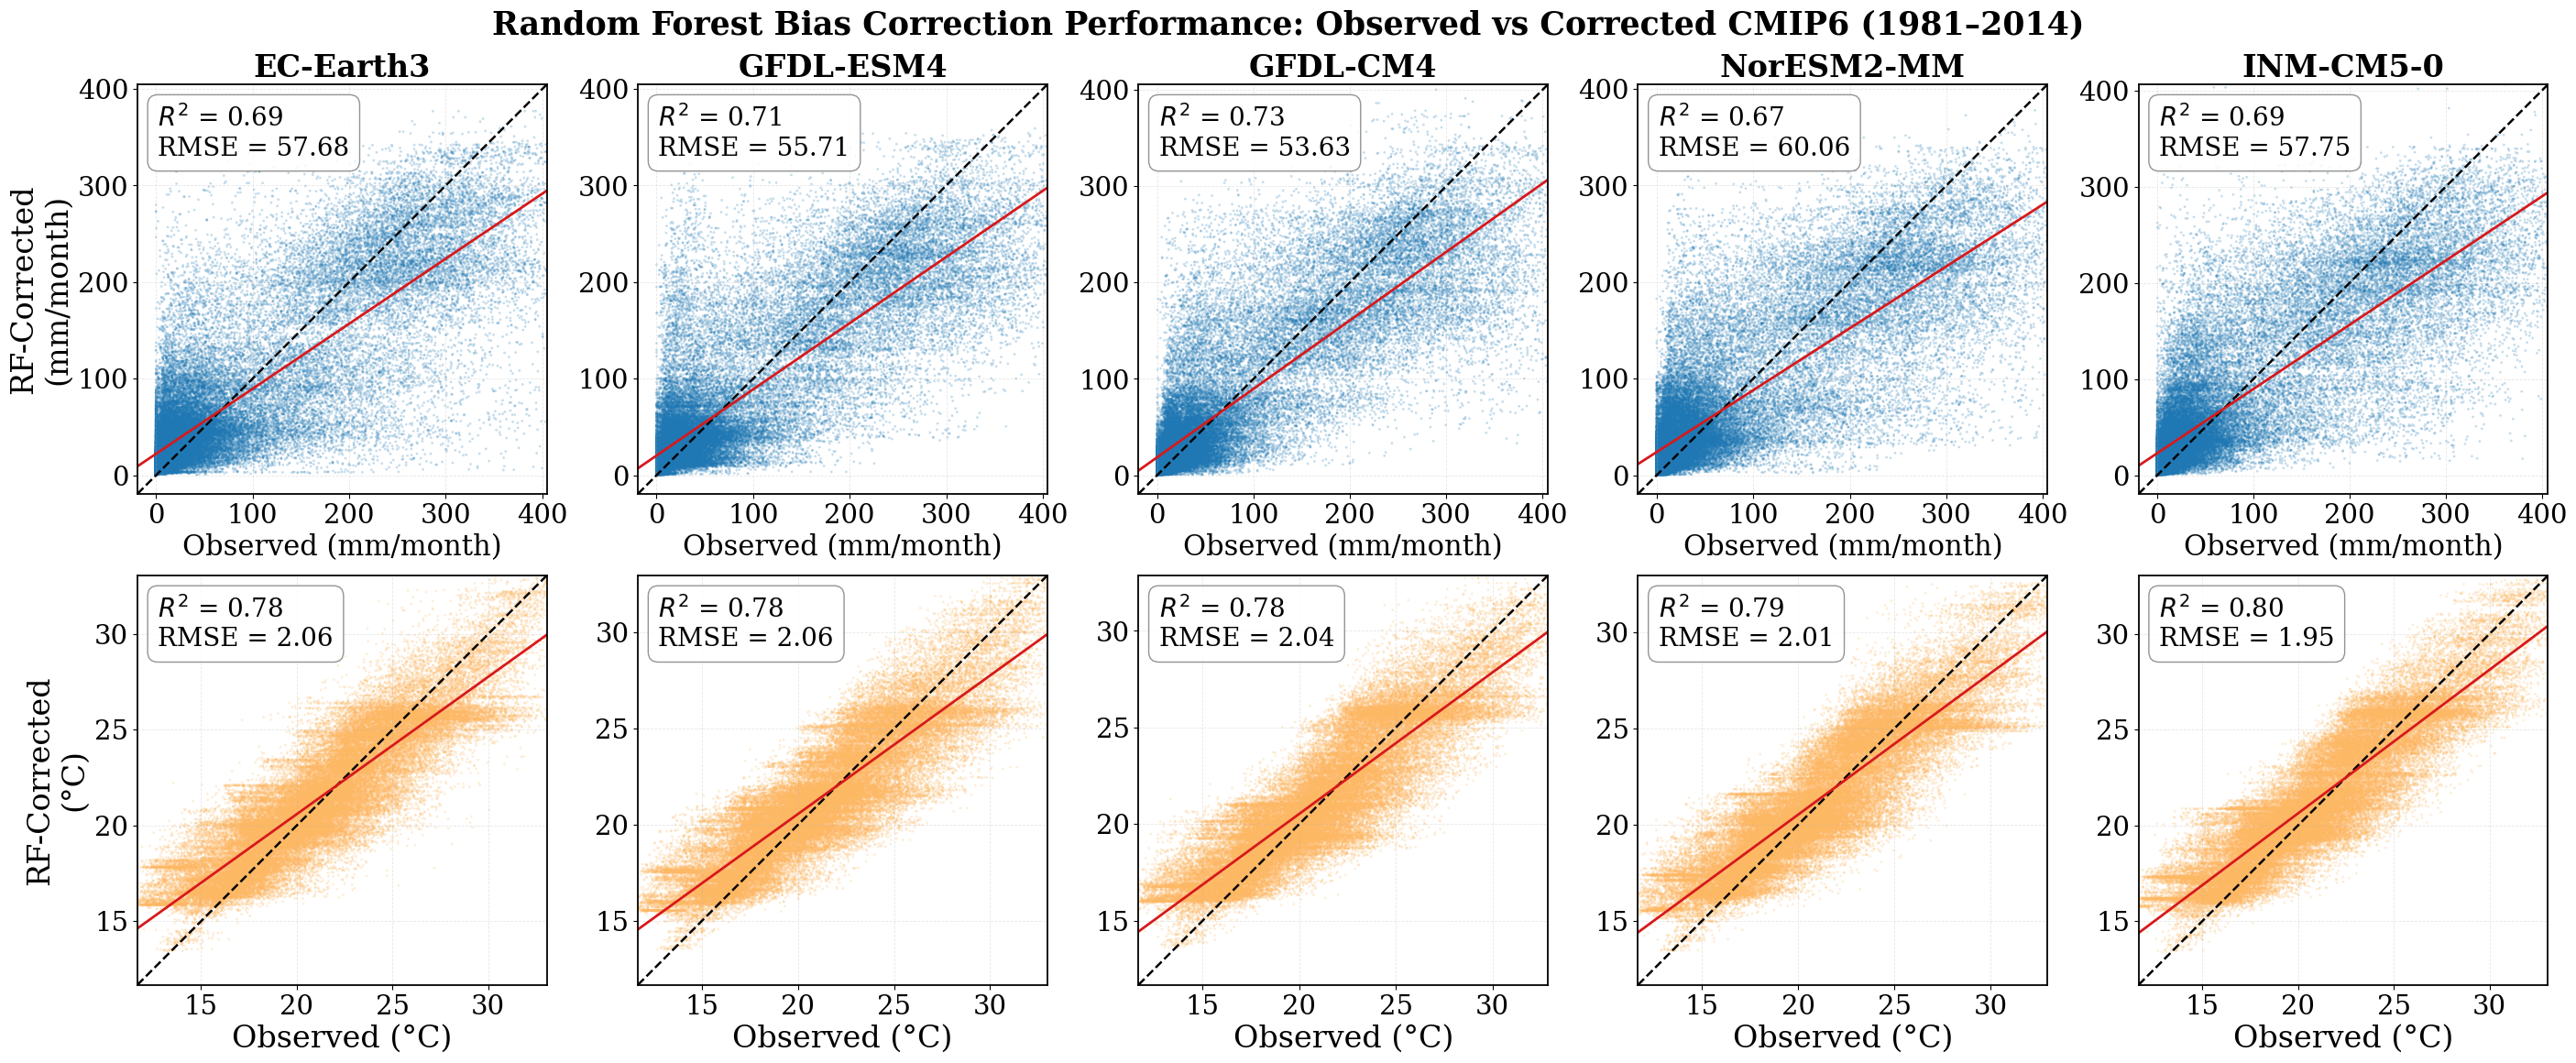


Saved: C:\Users\gerii\Documents\projects\tekeze\RF_BiasCorrection_Scatter_10panel.png

Finished Successfully.


In [2]:
# =============================================================================
# EVALUATION OF RANDOM FOREST BIAS CORRECTION PERFORMANCE
# =============================================================================
#
# Compares Observed (CHIRPS for PR, ERA5-Land for TA) against
# RF-bias-corrected CMIP6 outputs for 5 models, historical period 1981-2014.
#
# APPROACH:
#   - Use ALL pixels over the basin (not just basin mean) pooled across
#     all 408 historical months -> large sample size per panel
#   - One PNG: 2 rows (PR, TA) x 5 columns (models) = 10 panels
#   - Each panel: scatter of Observed vs RF-corrected, 1:1 line,
#     regression fit, R² and RMSE annotation
#
# INPUT:
#   Observed PR : CHIRPS_resampled\yyyy_mm.tif
#   Observed TA : ERA5_resampled\yyyy_mm.tif
#   Corrected   : NEX-GDDP-CMIP6\pr_corrected_RF\{model}\historical\yyyy_mm.tif
#                 NEX-GDDP-CMIP6\ta_corrected_RF\{model}\historical\yyyy_mm.tif
#
# OUTPUT:
#   C:\Users\gerii\Documents\projects\tekeze\RF_BiasCorrection_Scatter_10panel.png
# =============================================================================

import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error

# =============================================================================
# PATHS
# =============================================================================

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze"

OBS_DIRS = {
    "pr": os.path.join(BASE_DIR, "CHIRPS_resampled"),
    "ta": os.path.join(BASE_DIR, "ERA5_resampled"),
}

CORR_DIRS = {
    "pr": os.path.join(BASE_DIR, "NEX-GDDP-CMIP6", "pr_corrected_RF"),
    "ta": os.path.join(BASE_DIR, "NEX-GDDP-CMIP6", "ta_corrected_RF"),
}

OUT_PNG = os.path.join(BASE_DIR, "RF_BiasCorrection_Scatter_10panel.png")

MODELS = ['EC-Earth3', 'GFDL-ESM4', 'GFDL-CM4', 'NorESM2-MM', 'INM-CM5-0']

CALIB_START = 1981
CALIB_END   = 2014

# subsample to keep plotting fast and file size reasonable while still
# representing the full spatial+temporal distribution
MAX_POINTS_PER_PANEL = 60000

SEED = 42
rng  = np.random.default_rng(SEED)

# =============================================================================
# STYLE SETTINGS
# =============================================================================

FS = 24

plt.rcParams.update({
    "font.size":         FS,
    "axes.titlesize":    FS,
    "axes.labelsize":    FS,
    "xtick.labelsize":   FS - 3,
    "ytick.labelsize":   FS - 3,
    "legend.fontsize":   FS - 5,
    "font.family":       "serif",
    "axes.linewidth":    1.3,
})

POINT_COLORS = {
    "pr": "#1f78b4",   # blue
    "ta": "#fdb863",   # light orange/yellow
}

VAR_LABELS = {
    "pr": {"name": "Precipitation", "unit": "mm/month", "obs": "CHIRPS"},
    "ta": {"name": "Air Temperature", "unit": "°C", "obs": "ERA5-Land"},
}

# =============================================================================
# HELPER: build list of yyyy_mm keys for the calibration period
# =============================================================================

def get_keys(start_year, end_year):
    keys = []
    for y in range(start_year, end_year + 1):
        for m in range(1, 13):
            keys.append(f"{y}_{m:02d}")
    return keys

CALIB_KEYS = get_keys(CALIB_START, CALIB_END)

# =============================================================================
# HELPER: load a single band, masking nodata
# =============================================================================

def load_band(path):
    with rasterio.open(path) as src:
        arr = src.read(1).astype(np.float32)
        nodata = src.nodata
    if nodata is not None:
        arr[arr == nodata] = np.nan
    arr[arr <= -9999] = np.nan
    return arr

# =============================================================================
# HELPER: pool all pixels across all months for one variable/model pair
# =============================================================================

def pool_obs_vs_corrected(var, model):
    """
    Loop through all calibration months, load matching observed and
    RF-corrected TIFs, flatten to 1D, and concatenate across all months.
    Returns two 1D numpy arrays: obs_values, corrected_values
    (NaNs removed, paired).
    """

    obs_dir  = OBS_DIRS[var]
    corr_dir = os.path.join(CORR_DIRS[var], model, "historical")

    obs_list  = []
    corr_list = []

    for key in CALIB_KEYS:

        obs_path  = os.path.join(obs_dir,  f"{key}.tif")
        corr_path = os.path.join(corr_dir, f"{key}.tif")

        if not (os.path.exists(obs_path) and os.path.exists(corr_path)):
            continue

        obs_arr  = load_band(obs_path)
        corr_arr = load_band(corr_path)

        # ensure same shape (resample handled upstream; if mismatched, skip)
        if obs_arr.shape != corr_arr.shape:
            print(f"    WARNING: shape mismatch for {var} {model} {key} "
                  f"obs={obs_arr.shape} corr={corr_arr.shape} — skipping month")
            continue

        obs_flat  = obs_arr.flatten()
        corr_flat = corr_arr.flatten()

        valid = (~np.isnan(obs_flat)) & (~np.isnan(corr_flat))

        obs_list.append(obs_flat[valid])
        corr_list.append(corr_flat[valid])

    if len(obs_list) == 0:
        return np.array([]), np.array([])

    obs_all  = np.concatenate(obs_list)
    corr_all = np.concatenate(corr_list)

    return obs_all, corr_all

# =============================================================================
# HELPER: subsample large point clouds for manageable plotting
# =============================================================================

def subsample(x, y, max_points):
    if len(x) <= max_points:
        return x, y
    idx = rng.choice(len(x), size=max_points, replace=False)
    return x[idx], y[idx]

# =============================================================================
# MAIN: COMPUTE DATA FOR ALL 10 PANELS
# =============================================================================

print("=" * 65)
print("EVALUATING RF BIAS CORRECTION — PR and TA, all pixels pooled")
print("=" * 65)

panel_data = {}   # (var, model) -> dict with obs, corr, r2, rmse, n

for var in ["pr", "ta"]:
    for model in MODELS:

        print(f"\n  Processing {var.upper()} | {model} ...")

        obs_vals, corr_vals = pool_obs_vs_corrected(var, model)

        if len(obs_vals) == 0:
            print(f"    WARNING: No paired data found — panel will show 'No Data'")
            panel_data[(var, model)] = None
            continue

        r2   = r2_score(obs_vals, corr_vals)
        rmse = np.sqrt(mean_squared_error(obs_vals, corr_vals))

        print(f"    N pooled pixels x months : {len(obs_vals):,}")
        print(f"    R²   = {r2:.3f}")
        print(f"    RMSE = {rmse:.3f}")

        # subsample for plotting only (metrics computed on FULL data above)
        obs_plot, corr_plot = subsample(obs_vals, corr_vals, MAX_POINTS_PER_PANEL)

        panel_data[(var, model)] = {
            "obs_full":  obs_vals,
            "corr_full": corr_vals,
            "obs_plot":  obs_plot,
            "corr_plot": corr_plot,
            "r2":   r2,
            "rmse": rmse,
            "n":    len(obs_vals),
        }

# =============================================================================
# PLOT: 2 rows x 5 cols
# =============================================================================

print("\nGenerating 10-panel scatter plot ...")

fig, axes = plt.subplots(
    nrows=2, ncols=5,
    figsize=(28, 11),
    constrained_layout=True
)

for i, var in enumerate(["pr", "ta"]):
    for j, model in enumerate(MODELS):

        ax   = axes[i, j]
        data = panel_data.get((var, model))

        if data is None:
            ax.text(0.5, 0.5, "No Data",
                    ha="center", va="center", fontsize=FS - 2)
            ax.set_xticks([])
            ax.set_yticks([])
            continue

        obs_plot  = data["obs_plot"]
        corr_plot = data["corr_plot"]
        r2_val    = data["r2"]
        rmse_val  = data["rmse"]

        # axis limits — robust to outliers using 0.5/99.5 percentile
        lo = np.nanpercentile(np.concatenate([obs_plot, corr_plot]), 0.5)
        hi = np.nanpercentile(np.concatenate([obs_plot, corr_plot]), 99.5)
        pad = (hi - lo) * 0.05
        lo, hi = lo - pad, hi + pad

        # scatter
        ax.scatter(
            obs_plot, corr_plot,
            s=4, alpha=0.25,
            color=POINT_COLORS[var],
            edgecolors="none",
            rasterized=True
        )

        # 1:1 line
        ax.plot([lo, hi], [lo, hi], color="black",
                linewidth=1.8, linestyle="--", label="1:1 line")

        # regression fit (computed on full data for accuracy)
        m, b = np.polyfit(data["obs_full"], data["corr_full"], 1)
        x_fit = np.linspace(lo, hi, 200)
        ax.plot(x_fit, m * x_fit + b, color="#d7191c",
                linewidth=2.0, label=f"Fit")

        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)
        ax.set_aspect("equal", adjustable="box")

        # titles only on top row — model names
        if i == 0:
            ax.set_title(model, fontsize=FS, fontweight="bold")

        # row labels only on first column — variable names
        if j == 0:
            var_info = VAR_LABELS[var]
            ax.set_ylabel(
                f"RF-Corrected \n({var_info['unit']})",
                fontsize=FS
            )

        # x-label only on bottom row
        if i == 1:
            var_info = VAR_LABELS[var]
            ax.set_xlabel(
                f"Observed ({var_info['unit']})",
                fontsize=FS
            )
        else:
            var_info = VAR_LABELS[var]
            ax.set_xlabel(
                f"Observed ({var_info['unit']})",
                fontsize=FS - 2
            )

        # metrics box
        stats_text = f"$R^2$ = {r2_val:.2f}\nRMSE = {rmse_val:.2f}"
        ax.text(
            0.05, 0.95, stats_text,
            transform=ax.transAxes,
            fontsize=FS - 4,
            verticalalignment="top",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                      edgecolor="grey", alpha=0.85)
        )

        ax.tick_params(axis="both", which="major")
        ax.grid(True, linestyle="--", alpha=0.3, linewidth=0.6)

# =============================================================================
# ROW LABELS ON LEFT SIDE (Precipitation / Temperature) — extra annotation
# =============================================================================

#fig.text(0.005, 0.76, "Precipitation", rotation=90,
          #fontsize=FS, va="center")
#fig.text(0.005, 0.28, "Air Temperature", rotation=90,
         # fontsize=FS, va="center")

# =============================================================================
# OVERALL TITLE
# =============================================================================

fig.suptitle(
    "Random Forest Bias Correction Performance: Observed vs Corrected CMIP6 (1981–2014)",
    fontsize=FS + 1, fontweight="bold", y=1.04
)

# =============================================================================
# SAVE
# =============================================================================

plt.savefig(OUT_PNG, dpi=450, bbox_inches="tight")
plt.show()
plt.close()

print(f"\nSaved: {OUT_PNG}")
print("\nFinished Successfully.")

EVALUATING RF BIAS CORRECTION — PR and TA, all pixels pooled

  Processing PR | EC-Earth3 ...
    N pooled pixels x months : 59,568
    R²   = 0.691
    RMSE = 57.680

  Processing PR | GFDL-ESM4 ...
    N pooled pixels x months : 59,568
    R²   = 0.712
    RMSE = 55.713

  Processing PR | GFDL-CM4 ...
    N pooled pixels x months : 59,568
    R²   = 0.733
    RMSE = 53.629

  Processing PR | NorESM2-MM ...
    N pooled pixels x months : 59,568
    R²   = 0.665
    RMSE = 60.059

  Processing PR | INM-CM5-0 ...
    N pooled pixels x months : 59,568
    R²   = 0.691
    RMSE = 57.746

  Processing TA | EC-Earth3 ...
    N pooled pixels x months : 59,568
    R²   = 0.776
    RMSE = 2.064

  Processing TA | GFDL-ESM4 ...
    N pooled pixels x months : 59,568
    R²   = 0.776
    RMSE = 2.061

  Processing TA | GFDL-CM4 ...
    N pooled pixels x months : 59,568
    R²   = 0.781
    RMSE = 2.039

  Processing TA | NorESM2-MM ...
    N pooled pixels x months : 59,568
    R²   = 0.787
    RM

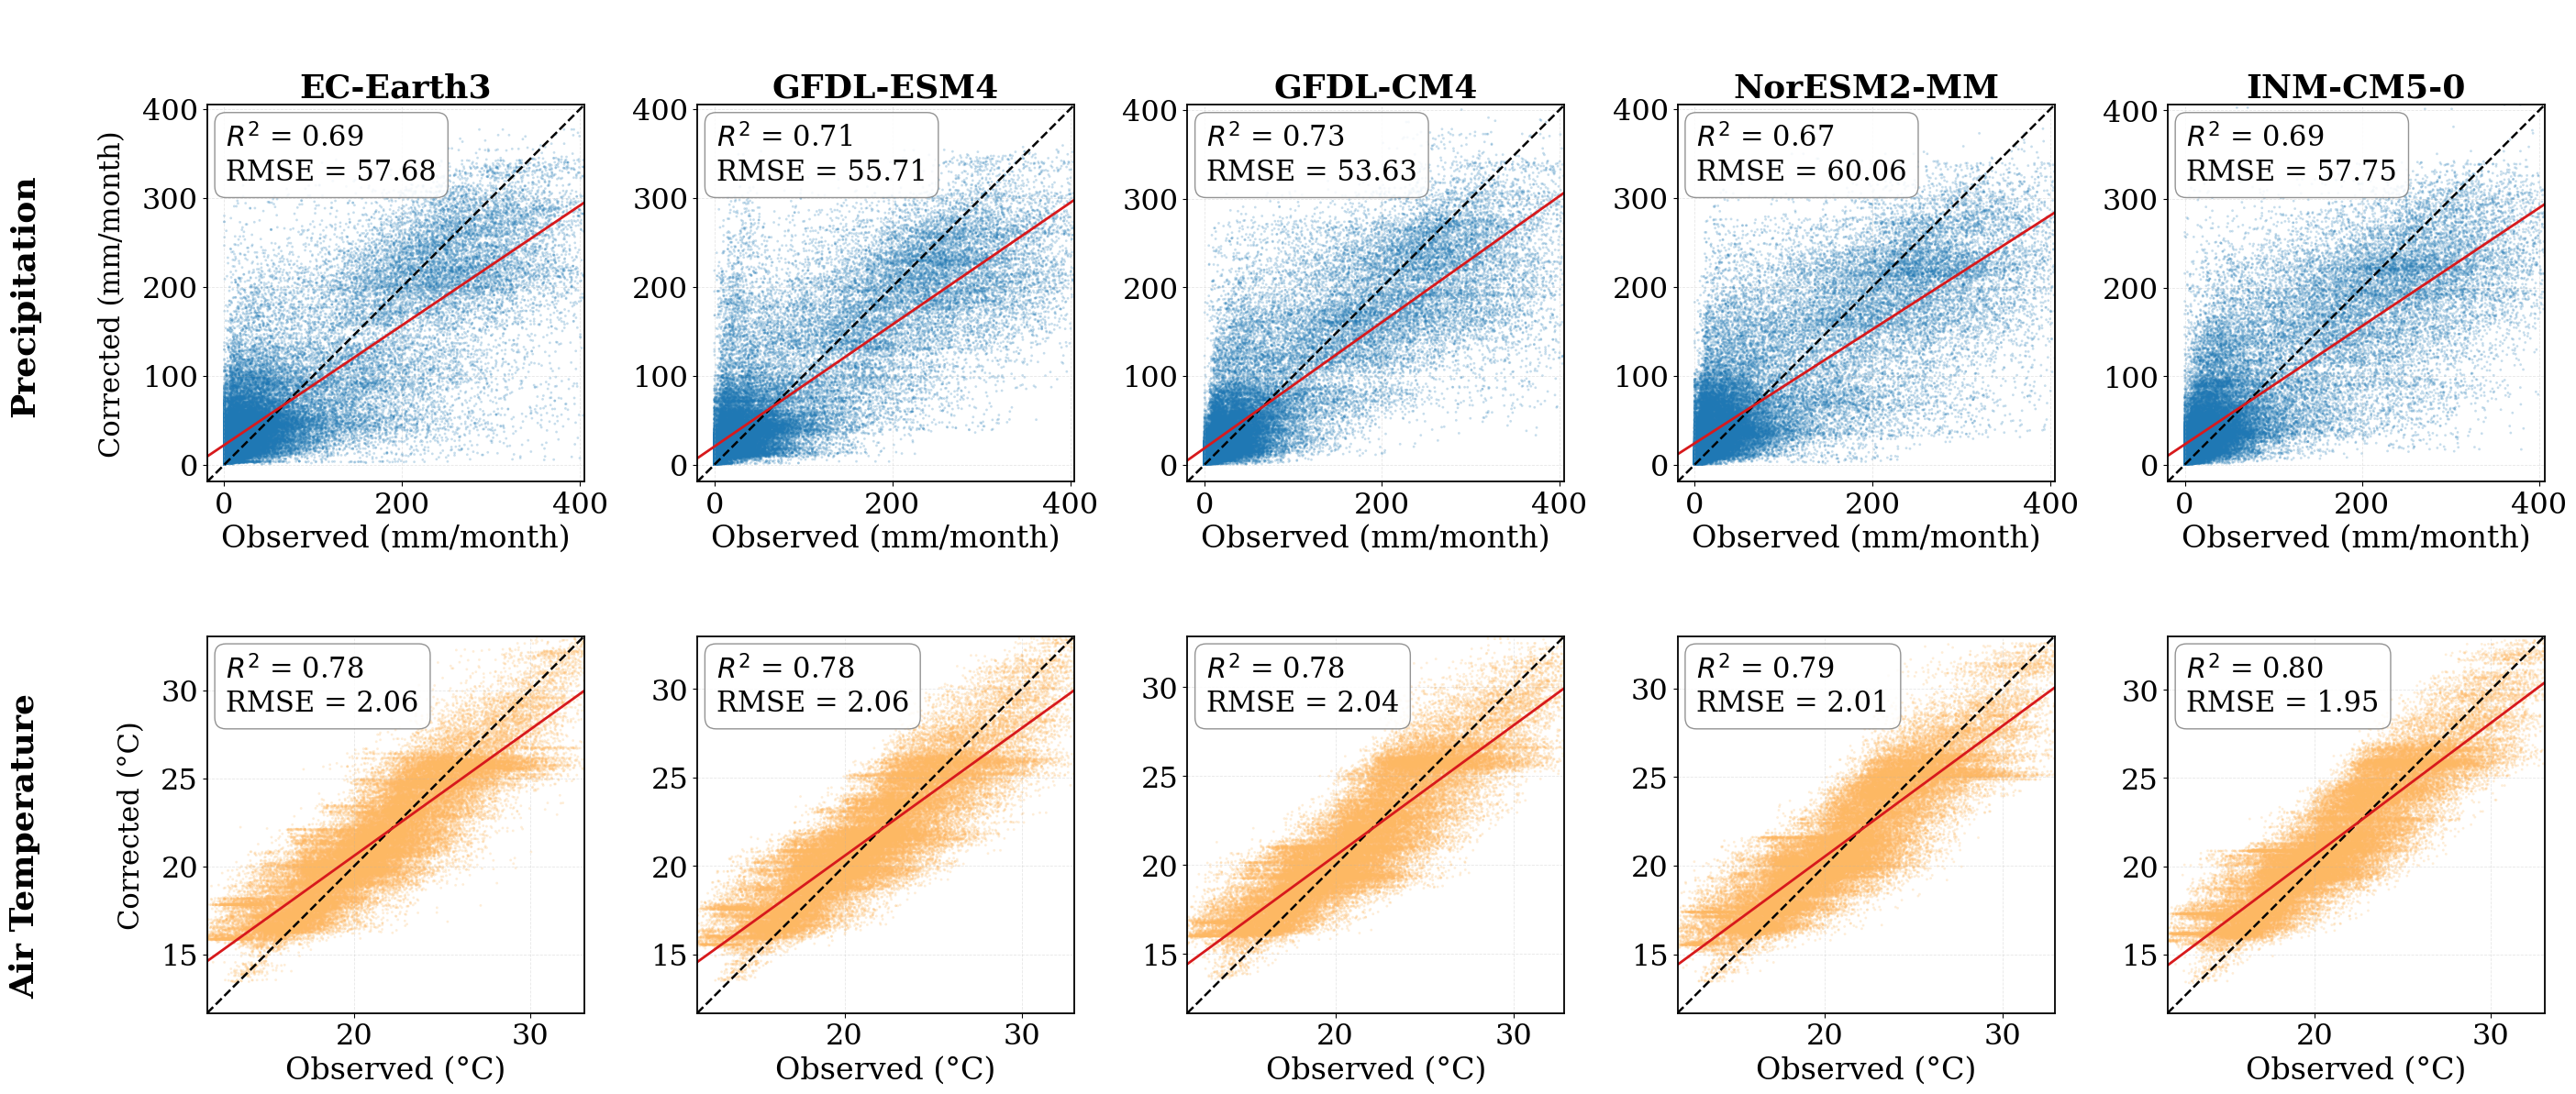


Saved: C:\Users\gerii\Documents\projects\tekeze\RF_BiasCorrection_Scatter_10panel.png

Finished Successfully.


In [5]:
# =============================================================================
# EVALUATION OF RANDOM FOREST BIAS CORRECTION PERFORMANCE
# =============================================================================
#
# Compares Observed (CHIRPS for PR, ERA5-Land for TA) against
# RF-bias-corrected CMIP6 outputs for 5 models, historical period 1981-2014.
#
# APPROACH:
#   - Use ALL pixels over the basin (not just basin mean) pooled across
#     all 408 historical months -> large sample size per panel
#   - One PNG: 2 rows (PR, TA) x 5 columns (models) = 10 panels
#   - Each panel: scatter of Observed vs RF-corrected, 1:1 line,
#     regression fit, R² and RMSE annotation
#
# INPUT:
#   Observed PR : CHIRPS_resampled\yyyy_mm.tif
#   Observed TA : ERA5_resampled\yyyy_mm.tif
#   Corrected   : NEX-GDDP-CMIP6\pr_corrected_RF\{model}\historical\yyyy_mm.tif
#                 NEX-GDDP-CMIP6\ta_corrected_RF\{model}\historical\yyyy_mm.tif
#
# OUTPUT:
#   C:\Users\gerii\Documents\projects\tekeze\RF_BiasCorrection_Scatter_10panel.png
# =============================================================================

import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error

# =============================================================================
# PATHS
# =============================================================================

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze"

OBS_DIRS = {
    "pr": os.path.join(BASE_DIR, "CHIRPS_resampled"),
    "ta": os.path.join(BASE_DIR, "ERA5_resampled"),
}

CORR_DIRS = {
    "pr": os.path.join(BASE_DIR, "NEX-GDDP-CMIP6", "pr_corrected_RF"),
    "ta": os.path.join(BASE_DIR, "NEX-GDDP-CMIP6", "ta_corrected_RF"),
}

OUT_PNG = os.path.join(BASE_DIR, "RF_BiasCorrection_Scatter_10panel.png")

MODELS = ['EC-Earth3', 'GFDL-ESM4', 'GFDL-CM4', 'NorESM2-MM', 'INM-CM5-0']

CALIB_START = 1981
CALIB_END   = 2014

# subsample to keep plotting fast and file size reasonable while still
# representing the full spatial+temporal distribution
MAX_POINTS_PER_PANEL = 60000

SEED = 42
rng  = np.random.default_rng(SEED)

# =============================================================================
# STYLE SETTINGS
# =============================================================================

FS = 26

plt.rcParams.update({
    "font.size":         FS,
    "axes.titlesize":    FS,
    "axes.labelsize":    FS,
    "xtick.labelsize":   FS - 3,
    "ytick.labelsize":   FS - 3,
    "legend.fontsize":   FS - 5,
    "font.family":       "serif",
    "axes.linewidth":    1.3,
})

POINT_COLORS = {
    "pr": "#1f78b4",   # blue
    "ta": "#fdb863",   # light orange/yellow
}

VAR_LABELS = {
    "pr": {"name": "Precipitation", "unit": "mm/month", "obs": "CHIRPS"},
    "ta": {"name": "Air Temperature", "unit": "°C", "obs": "ERA5-Land"},
}

# =============================================================================
# HELPER: build list of yyyy_mm keys for the calibration period
# =============================================================================

def get_keys(start_year, end_year):
    keys = []
    for y in range(start_year, end_year + 1):
        for m in range(1, 13):
            keys.append(f"{y}_{m:02d}")
    return keys

CALIB_KEYS = get_keys(CALIB_START, CALIB_END)

# =============================================================================
# HELPER: load a single band, masking nodata
# =============================================================================

def load_band(path):
    with rasterio.open(path) as src:
        arr = src.read(1).astype(np.float32)
        nodata = src.nodata
    if nodata is not None:
        arr[arr == nodata] = np.nan
    arr[arr <= -9999] = np.nan
    return arr

# =============================================================================
# HELPER: pool all pixels across all months for one variable/model pair
# =============================================================================

def pool_obs_vs_corrected(var, model):
    """
    Loop through all calibration months, load matching observed and
    RF-corrected TIFs, flatten to 1D, and concatenate across all months.
    Returns two 1D numpy arrays: obs_values, corrected_values
    (NaNs removed, paired).
    """

    obs_dir  = OBS_DIRS[var]
    corr_dir = os.path.join(CORR_DIRS[var], model, "historical")

    obs_list  = []
    corr_list = []

    for key in CALIB_KEYS:

        obs_path  = os.path.join(obs_dir,  f"{key}.tif")
        corr_path = os.path.join(corr_dir, f"{key}.tif")

        if not (os.path.exists(obs_path) and os.path.exists(corr_path)):
            continue

        obs_arr  = load_band(obs_path)
        corr_arr = load_band(corr_path)

        # ensure same shape (resample handled upstream; if mismatched, skip)
        if obs_arr.shape != corr_arr.shape:
            print(f"    WARNING: shape mismatch for {var} {model} {key} "
                  f"obs={obs_arr.shape} corr={corr_arr.shape} — skipping month")
            continue

        obs_flat  = obs_arr.flatten()
        corr_flat = corr_arr.flatten()

        valid = (~np.isnan(obs_flat)) & (~np.isnan(corr_flat))

        obs_list.append(obs_flat[valid])
        corr_list.append(corr_flat[valid])

    if len(obs_list) == 0:
        return np.array([]), np.array([])

    obs_all  = np.concatenate(obs_list)
    corr_all = np.concatenate(corr_list)

    return obs_all, corr_all

# =============================================================================
# HELPER: subsample large point clouds for manageable plotting
# =============================================================================

def subsample(x, y, max_points):
    if len(x) <= max_points:
        return x, y
    idx = rng.choice(len(x), size=max_points, replace=False)
    return x[idx], y[idx]

# =============================================================================
# MAIN: COMPUTE DATA FOR ALL 10 PANELS
# =============================================================================

print("=" * 65)
print("EVALUATING RF BIAS CORRECTION — PR and TA, all pixels pooled")
print("=" * 65)

panel_data = {}   # (var, model) -> dict with obs, corr, r2, rmse, n

for var in ["pr", "ta"]:
    for model in MODELS:

        print(f"\n  Processing {var.upper()} | {model} ...")

        obs_vals, corr_vals = pool_obs_vs_corrected(var, model)

        if len(obs_vals) == 0:
            print(f"    WARNING: No paired data found — panel will show 'No Data'")
            panel_data[(var, model)] = None
            continue

        r2   = r2_score(obs_vals, corr_vals)
        rmse = np.sqrt(mean_squared_error(obs_vals, corr_vals))

        print(f"    N pooled pixels x months : {len(obs_vals):,}")
        print(f"    R²   = {r2:.3f}")
        print(f"    RMSE = {rmse:.3f}")

        # subsample for plotting only (metrics computed on FULL data above)
        obs_plot, corr_plot = subsample(obs_vals, corr_vals, MAX_POINTS_PER_PANEL)

        panel_data[(var, model)] = {
            "obs_full":  obs_vals,
            "corr_full": corr_vals,
            "obs_plot":  obs_plot,
            "corr_plot": corr_plot,
            "r2":   r2,
            "rmse": rmse,
            "n":    len(obs_vals),
        }

# =============================================================================
# PLOT: 2 rows x 5 cols
# =============================================================================

print("\nGenerating 10-panel scatter plot ...")

fig, axes = plt.subplots(
    nrows=2, ncols=5,
    figsize=(28, 12.5),
    constrained_layout=False
)

fig.subplots_adjust(
    hspace=0.30,   # vertical gap between PR row and TA row
    wspace=0.30,   # horizontal gap between model columns
    left=0.07,
    right=0.98,
    top=0.90,
    bottom=0.08
)

for i, var in enumerate(["pr", "ta"]):
    for j, model in enumerate(MODELS):

        ax   = axes[i, j]
        data = panel_data.get((var, model))

        if data is None:
            ax.text(0.5, 0.5, "No Data",
                    ha="center", va="center", fontsize=FS - 2)
            ax.set_xticks([])
            ax.set_yticks([])
            continue

        obs_plot  = data["obs_plot"]
        corr_plot = data["corr_plot"]
        r2_val    = data["r2"]
        rmse_val  = data["rmse"]

        # axis limits — robust to outliers using 0.5/99.5 percentile
        lo = np.nanpercentile(np.concatenate([obs_plot, corr_plot]), 0.5)
        hi = np.nanpercentile(np.concatenate([obs_plot, corr_plot]), 99.5)
        pad = (hi - lo) * 0.05
        lo, hi = lo - pad, hi + pad

        # scatter
        ax.scatter(
            obs_plot, corr_plot,
            s=4, alpha=0.25,
            color=POINT_COLORS[var],
            edgecolors="none",
            rasterized=True
        )

        # 1:1 line
        ax.plot([lo, hi], [lo, hi], color="black",
                linewidth=1.8, linestyle="--", label="1:1 line")

        # regression fit (computed on full data for accuracy)
        m, b = np.polyfit(data["obs_full"], data["corr_full"], 1)
        x_fit = np.linspace(lo, hi, 200)
        ax.plot(x_fit, m * x_fit + b, color="#d7191c",
                linewidth=2.0, label=f"Fit")

        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)
        ax.set_aspect("equal", adjustable="box")

        # titles only on top row — model names
        if i == 0:
            ax.set_title(model, fontsize=FS, fontweight="bold")

        # row labels only on first column — variable unit (row name added via fig.text)
        if j == 0:
            var_info = VAR_LABELS[var]
            ax.set_ylabel(
                f"Corrected ({var_info['unit']})",
                fontsize=FS - 4,
                labelpad=12
            )

        # x-label only on bottom row
        if i == 1:
            var_info = VAR_LABELS[var]
            ax.set_xlabel(
                f"Observed ({var_info['unit']})",
                fontsize=FS - 2
            )
        else:
            var_info = VAR_LABELS[var]
            ax.set_xlabel(
                f"Observed ({var_info['unit']})",
                fontsize=FS - 2
            )

        # metrics box
        stats_text = f"$R^2$ = {r2_val:.2f}\nRMSE = {rmse_val:.2f}"
        ax.text(
            0.05, 0.95, stats_text,
            transform=ax.transAxes,
            fontsize=FS - 4,
            verticalalignment="top",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                      edgecolor="grey", alpha=0.85)
        )

        ax.tick_params(axis="both", which="major")
        ax.grid(True, linestyle="--", alpha=0.3, linewidth=0.6)

# =============================================================================
# ROW LABELS ON LEFT SIDE (Precipitation / Temperature) — extra annotation
# =============================================================================

fig.text(-0.001, 0.72, "Precipitation", rotation=90,
          fontsize=FS, fontweight="bold", va="center", ha="center")
fig.text(-0.001, 0.24, "Air Temperature", rotation=90,
          fontsize=FS, fontweight="bold", va="center", ha="center")

# =============================================================================
# OVERALL TITLE
# =============================================================================

fig.suptitle(
    " ",
    fontsize=FS + 1, fontweight="bold", y=0.97
)

# =============================================================================
# SAVE
# =============================================================================

plt.savefig(OUT_PNG, dpi=450, bbox_inches="tight")
plt.show()
plt.close()

print(f"\nSaved: {OUT_PNG}")
print("\nFinished Successfully.")